In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import root_numpy
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def getData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    return pd.DataFrame(data, columns=dfNames)

In [4]:
def flatten(data, column):
    a = []
    for row in range(0,len(data)):
        a.append(data[row][column])
    return np.concatenate(a)

In [5]:
def getFlattenedData(branchNames, dfNames, inputFiles, treeName):
    data = root_numpy.root2array(inputFiles, treeName, branches=branchNames)
    a = []
    for branchName in branchNames:
        a.append(flatten(data, branchNames.index(branchName)))
    return pd.DataFrame(np.transpose(a), columns=dfNames)

In [6]:
def getRc(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    return (n_ss-n_os)/(n_ss+n_os)

In [7]:
def getRcs(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    return (n_ss-n_os)/(n_ss+n_os)

In [8]:
def getRcErr(dataframe):
    n_ss = sum(dataframe[dataframe.b==1]['w'])
    n_os = sum(dataframe[dataframe.b==-1]['w'])
    n_unweighted = dataframe[dataframe.b==1].shape[0] + dataframe[dataframe.b==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [9]:
def getRcsErr(dataframe):
    n_ss = sum(dataframe[dataframe.bs==1]['ws'])
    n_os = sum(dataframe[dataframe.bs==-1]['ws'])
    n_unweighted = dataframe[dataframe.bs==1].shape[0] + dataframe[dataframe.bs==-1].shape[0]
    #p = n_ss/(n_ss+n_os)
    return 2*np.sqrt( n_ss * n_os / ((n_ss+n_os)**2 * n_unweighted) )

In [10]:
def calc_hist(vals, bins=10, weights=None, density=False):
    
    if weights is None:
        weights = np.ones(vals.shape)
    
    # compute histogram
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    
    # compute which bins the values are in
    digits = np.digitize(vals, bins)

    # compute the errors per bin
    # note that lowest bin value that digitize returns is 1
    # hence the range in the following list comprehension should start at 1
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])

    # handle normalization
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
        
    return hist, errs, bins

In [11]:
observables1 = ['pt','b','dr','z','epair','w','reject']
observabless1 = ['pts','bs','drs','zs','epairs','ws','rejects']

In [60]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'(b!=0 or bs!=0) and bs!=-9 and b!=-9 and reject<=0 and rejects<=0 and 10<pts<30')

In [54]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [61]:
df.shape[0]

54302

In [62]:
df.eval('db = bs - b', inplace=True)
df.eval('dpt = pts - pt', inplace=True)

In [63]:
np.unique(df['db'])

array([-2, -1,  0,  1,  2], dtype=int32)

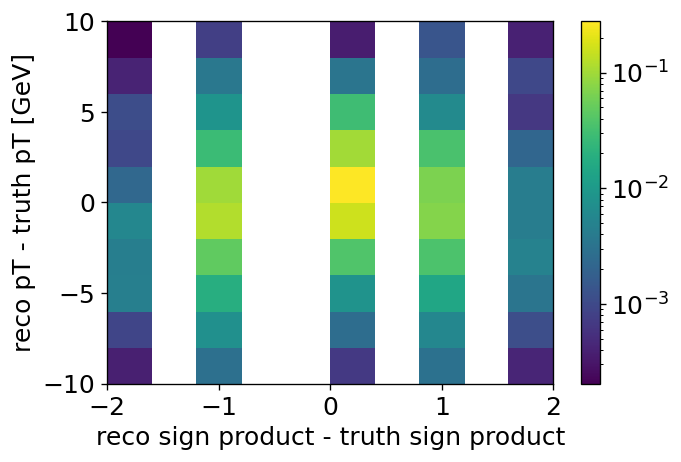

In [65]:
plt.hist2d(df['db'], df['dpt'], range=((-2,2),(-10,10)), density=True, weights=df['w'], norm=matplotlib.colors.LogNorm())
plt.xlabel('reco sign product - truth sign product')
plt.ylabel('reco pT - truth pT [GeV]')
plt.ylim(-10,10)
plt.colorbar()

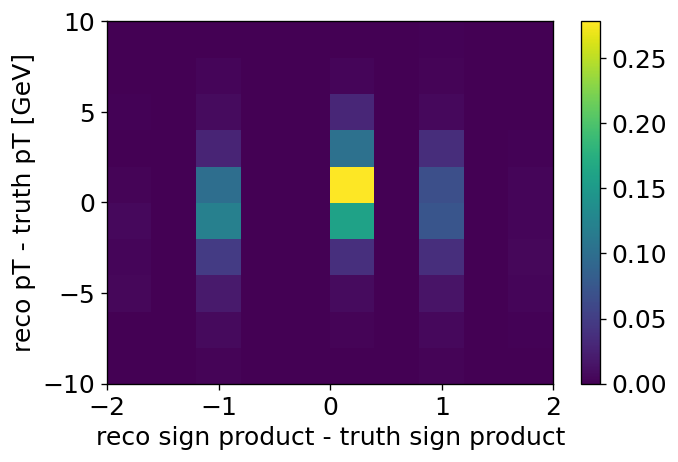

In [52]:
plt.hist2d(df['db'], df['dpt'], range=((-2,2),(-10,10)), density=True, weights=df['w'])
plt.xlabel('reco sign product - truth sign product')
plt.ylabel('reco pT - truth pT [GeV]')
plt.ylim(-10,10)
plt.colorbar()

In [22]:
df = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b!=0 and b!=-9 and reject<=0 and rejects<=0 and 10<pts<30')

In [14]:
rcs_0 = getRcs(applyCut(df,'10<pts<15'))
rcs_err_0 = getRcsErr(applyCut(df,'10<pts<15'))

In [15]:
rcs_1 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_1 = getRcsErr(applyCut(df,'15<pts<20'))

In [16]:
rcs_2 = getRcs(applyCut(df,'20<pts<30'))
rcs_err_2 = getRcsErr(applyCut(df,'20<pts<30'))

In [17]:
rc_0 = getRc(applyCut(df,'10<pts<15'))
rc_err_0 = getRcErr(applyCut(df,'10<pts<15'))

In [18]:
rc_1 = getRc(applyCut(df,'15<pts<20'))
rc_err_1 = getRcErr(applyCut(df,'15<pts<20'))

In [19]:
rc_2 = getRc(applyCut(df,'20<pts<30'))
rc_err_2 = getRcErr(applyCut(df,'20<pts<30'))

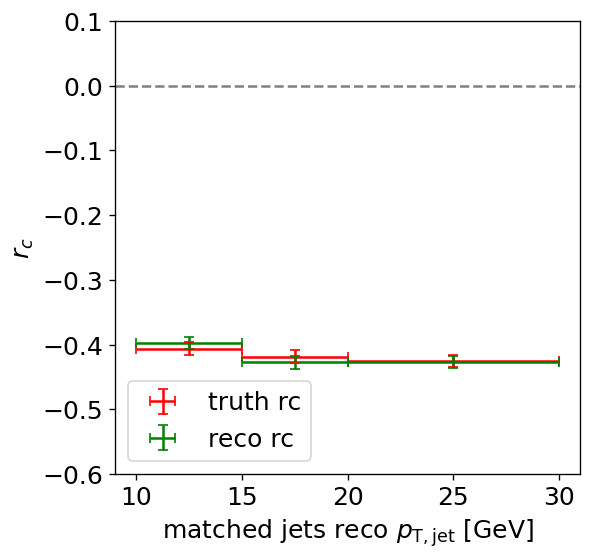

In [20]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='truth rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='reco rc')
plt.xlabel('matched jets reco $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

In [82]:
df_truptcut = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b!=0 and b!=-9 and reject<=0 and rejects<=0 and 10<pt<30')

In [83]:
rcs_0 = getRcs(applyCut(df_truptcut,'10<pt<15'))
rcs_err_0 = getRcsErr(applyCut(df_truptcut,'10<pt<15'))

In [84]:
rcs_1 = getRcs(applyCut(df_truptcut,'15<pt<20'))
rcs_err_1 = getRcsErr(applyCut(df_truptcut,'15<pt<20'))

In [85]:
rcs_2 = getRcs(applyCut(df_truptcut,'20<pt<30'))
rcs_err_2 = getRcsErr(applyCut(df_truptcut,'20<pt<30'))

In [86]:
rc_0 = getRc(applyCut(df_truptcut,'10<pt<15'))
rc_err_0 = getRcErr(applyCut(df_truptcut,'10<pt<15'))

In [87]:
rc_1 = getRc(applyCut(df_truptcut,'15<pt<20'))
rc_err_1 = getRcErr(applyCut(df_truptcut,'15<pt<20'))

In [88]:
rc_2 = getRc(applyCut(df_truptcut,'20<pt<30'))
rc_err_2 = getRcErr(applyCut(df_truptcut,'20<pt<30'))

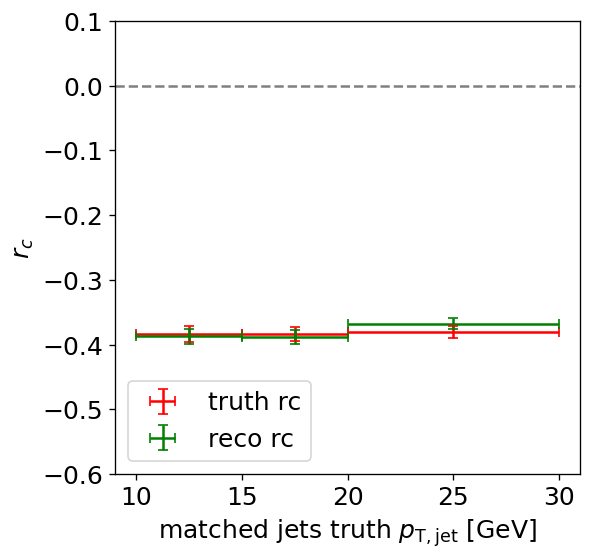

In [89]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='truth rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='reco rc')
plt.xlabel('matched jets truth $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

In [29]:
rcs_0 = getRcs(applyCut(df,'10<pts<15'))
rcs_err_0 = getRcsErr(applyCut(df,'10<pts<15'))

In [30]:
rcs_1 = getRcs(applyCut(df,'15<pts<20'))
rcs_err_1 = getRcsErr(applyCut(df,'15<pts<20'))

In [31]:
rcs_2 = getRcs(applyCut(df,'20<pts<30'))
rcs_err_2 = getRcsErr(applyCut(df,'20<pts<30'))

In [40]:
df_truptcut = applyCut(getData(observables1+observabless1, observables1+observabless1, '$HOME/output/run12/all_pid_new.root', "MatchedTree"),'bs!=0 and bs!=-9 and b!=0 and b!=-9 and reject<=0 and rejects<=0 and 10<pt<30')

In [41]:
rc_0 = getRc(applyCut(df_truptcut,'10<pt<15'))
rc_err_0 = getRcErr(applyCut(df_truptcut,'10<pt<15'))

In [42]:
rc_1 = getRc(applyCut(df_truptcut,'15<pt<20'))
rc_err_1 = getRcErr(applyCut(df_truptcut,'15<pt<20'))

In [43]:
rc_2 = getRc(applyCut(df_truptcut,'20<pt<30'))
rc_err_2 = getRcErr(applyCut(df_truptcut,'20<pt<30'))

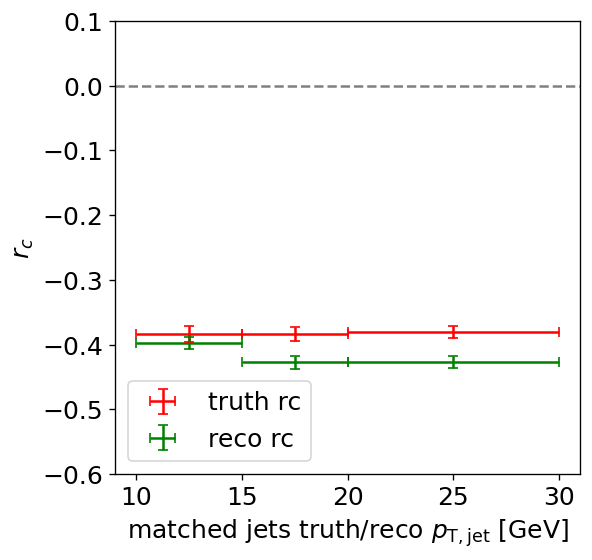

In [44]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='truth rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='reco rc')
plt.xlabel('matched jets truth/reco $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

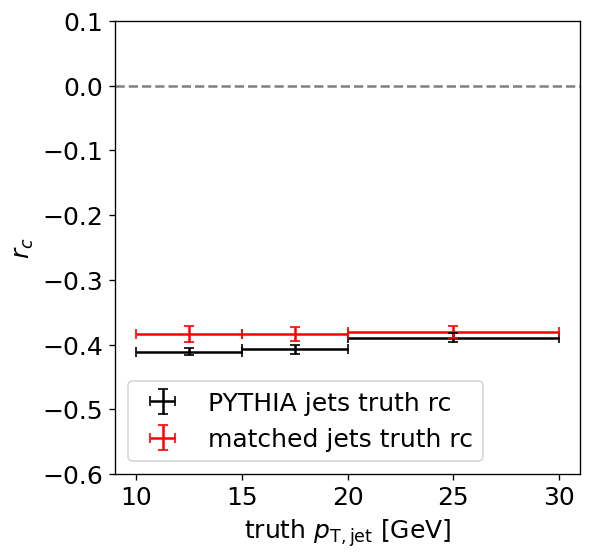

In [46]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [-0.411037,-0.406995,-0.389326], xerr=[2.5, 2.5, 5], yerr=[0.00528726, 0.0068786, 0.0065369], capsize=3, color='k', ls='none', label='PYTHIA jets truth rc')
plt.errorbar([12.5, 17.5, 25], [rc_0, rc_1, rc_2], xerr=[2.5, 2.5, 5], yerr=[rc_err_0, rc_err_1, rc_err_2], capsize=3, color='r', ls='none', label='matched jets truth rc')
plt.xlabel('truth $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

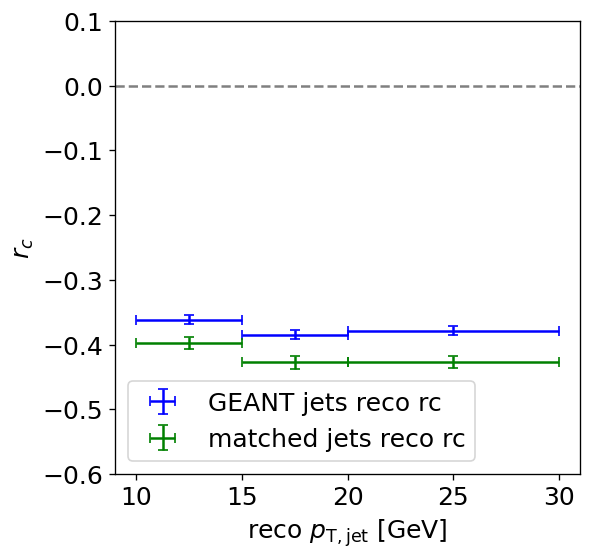

In [47]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([12.5, 17.5, 25], [-0.361889,-0.384597,-0.378657], xerr=[2.5, 2.5, 5], yerr=[0.00692934,0.00725826,0.00698842], capsize=3, color='b', ls='none', label='GEANT jets reco rc')
plt.errorbar([12.5, 17.5, 25], [rcs_0, rcs_1, rcs_2], xerr=[2.5, 2.5, 5], yerr=[rcs_err_0, rcs_err_1, rcs_err_2], capsize=3, color='g', ls='none', label='matched jets reco rc')
plt.xlabel('reco $p_{\mathrm{T, jet}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.legend()

In [13]:
df.eval('ts = 2*zs*(1-zs)*epairs/( ((1-zs)*epairs*sin(drs))**2 )', inplace=True)
#df.eval('ts = 2*(1-zs)/(zs*epairs*drs**2)', inplace=True)
df.eval('t = 2*z*(1-z)*epair/( ((1-z)*epair*sin(dr))**2 )', inplace=True)

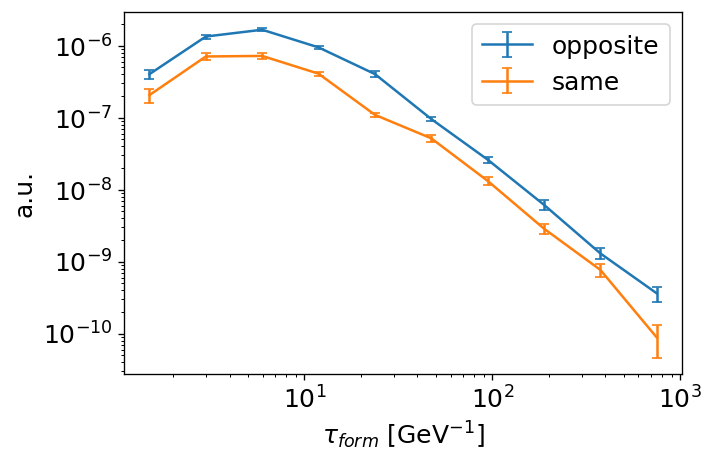

In [72]:
y_os, yerr_os = calc_hist(df[df.bs<0]['ts'], bins=bins, weights=df[df.bs<0]['w'])[:-1]
y_ss, yerr_ss = calc_hist(df[df.bs>0]['ts'], bins=bins, weights=df[df.bs>0]['w'])[:-1]
plt.errorbar(bincenter, y_os/(np.array(bins[1:])-np.array(bins[:-1])), yerr=yerr_os/(np.array(bins[1:])-np.array(bins[:-1])), label='opposite', capsize=3)
plt.errorbar(bincenter, y_ss/(np.array(bins[1:])-np.array(bins[:-1])), yerr=yerr_ss/(np.array(bins[1:])-np.array(bins[:-1])), label='same', capsize=3)
plt.xlabel(r'$\tau_{form}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.xscale('log')
#plt.xlim(0.1, 1e4)
plt.legend()
plt.ylabel('a.u.', fontsize=15)
plt.yscale('log')

In [41]:
print([rcs_0, rcs_1, rcs_2])
print([rcs_err_0, rcs_err_1, rcs_err_2])

[-0.4064533443942109, -0.4188521568845832, -0.42563071616487436]
[0.00990317124029046, 0.010044333823202564, 0.008944482151755102]


In [39]:
bins = 10.0**(np.arange(0,3.3,0.3))

In [40]:
bincenter = (bins[:-1] + bins[1:])/2

In [42]:
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = '15'

In [43]:
dfs = []
for i in range(0, len(bincenter)):
    dfs.append(df[np.logical_and(df.t>bins[i], df.t<bins[i+1])])

In [44]:
rc_0 = []
rc_err_0 = []
for i in range(0, len(dfs)):
    rc_0.append(getRc(applyCut(dfs[i],'10<pt<15')))
    rc_err_0.append(getRcErr(applyCut(dfs[i],'10<pt<15')))

In [45]:
rc_1 = []
rc_err_1 = []
for i in range(0, len(dfs)):
    rc_1.append(getRc(applyCut(dfs[i],'15<pt<20')))
    rc_err_1.append(getRcErr(applyCut(dfs[i],'15<pt<20')))

In [46]:
rc_2 = []
rc_err_2 = []
for i in range(0, len(dfs)):
    rc_2.append(getRc(applyCut(dfs[i],'20<pt<30')))
    rc_err_2.append(getRcErr(applyCut(dfs[i],'20<pt<30')))

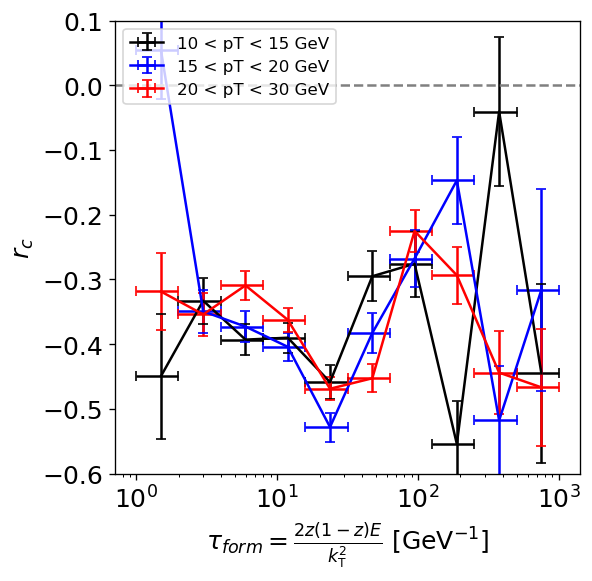

In [47]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rc_0, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_0, capsize=3, color='k', label='10 < pT < 15 GeV')
plt.errorbar(bincenter, rc_1, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_1, capsize=3, color='b', label='15 < pT < 20 GeV')
plt.errorbar(bincenter, rc_2, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_2, capsize=3, color='r', label='20 < pT < 30 GeV')
plt.xlabel(r'$\tau_{form} = \frac{2z(1-z)E}{k_{\mathrm{T}}^2}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
#plt.xlabel(r'$\tau_{form} = [2Ez(1-z)(1-\mathrm{cos}(\Delta R))]^{-1}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.xscale('log')
plt.legend(fontsize=10, loc='upper left')

In [31]:
# all pythia truth
rc_0_tru = np.array([-0.506609, -0.376323, -0.414772, -0.435353, -0.430815, -0.419878, -0.347681, -0.42523, -0.325158, -0.422264])
rc_1_tru = np.array([-0.224774, -0.289347, -0.41017, -0.396058, -0.507434, -0.407163, -0.398413, -0.32699, -0.155256, -0.143323])
rc_2_tru = np.array([-0.358098, -0.284425, -0.373438, -0.367739, -0.462602, -0.453729, -0.383587, -0.3694, -0.289624, -0.328626])
rc_err_0_tru = np.array([0.0384044, 0.0155302, 0.0108749, 0.0104916, 0.0122456, 0.016477, 0.0228347, 0.0317623, 0.0461435, 0.0604315])
rc_err_1_tru = np.array([0.0470999, 0.0228755, 0.0154026, 0.0144643, 0.0147605, 0.0197485, 0.0266783, 0.0391727, 0.0562894, 0.0816271])
rc_err_2_tru = np.array([0.0474006, 0.0255676, 0.0171612, 0.0142561, 0.0134144, 0.0163629, 0.0224578, 0.0302452, 0.0450201, 0.0641141])

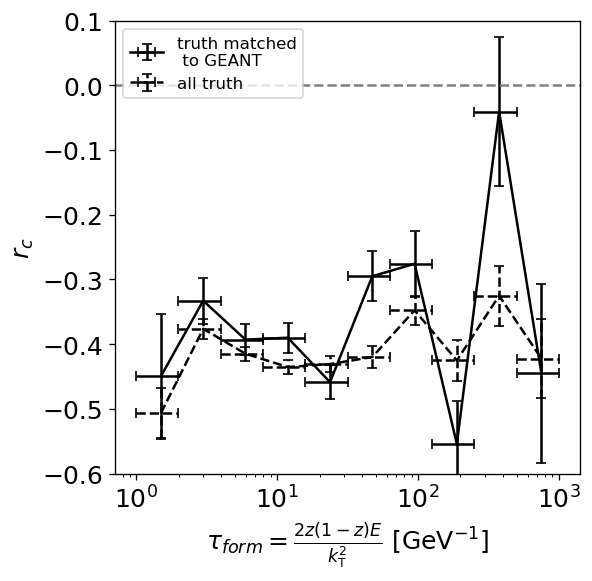

In [49]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rc_0, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_0, capsize=3, color='k', label='truth matched\n to GEANT')
eb1 = plt.errorbar(bincenter, rc_0_tru, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_0_tru, capsize=3, color='k', linestyle='--', label='all truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel(r'$\tau_{form} = \frac{2z(1-z)E}{k_{\mathrm{T}}^2}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.xscale('log')
plt.legend(fontsize=10, loc='upper left')

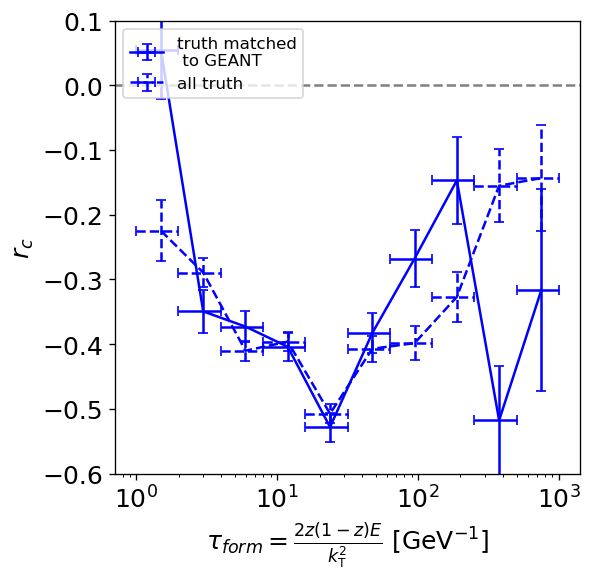

In [52]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rc_1, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_1, capsize=3, color='b', label='truth matched\n to GEANT')
eb1 = plt.errorbar(bincenter, rc_1_tru, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_1_tru, capsize=3, color='b', linestyle='--', label='all truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel(r'$\tau_{form} = \frac{2z(1-z)E}{k_{\mathrm{T}}^2}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.xscale('log')
plt.legend(fontsize=10, loc='upper left')

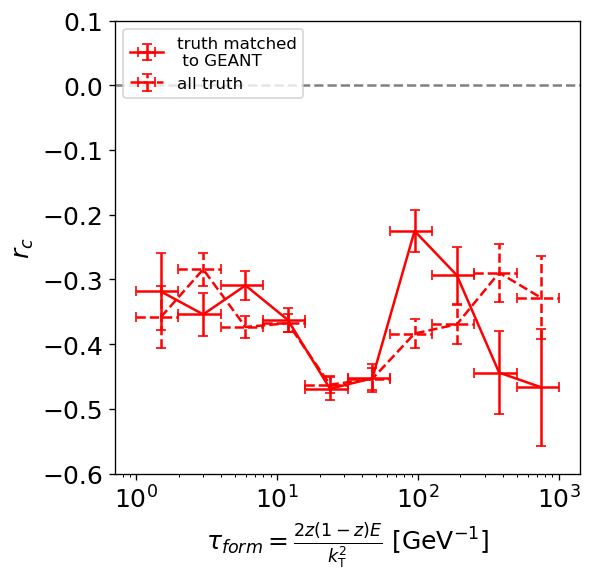

In [53]:
fig=plt.figure(figsize=(5,5))
plt.errorbar(bincenter, rc_2, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_2, capsize=3, color='r', label='truth matched\n to GEANT')
eb1 = plt.errorbar(bincenter, rc_2_tru, xerr=np.array(bincenter)-np.array(bins[:-1]), yerr=rc_err_2_tru, capsize=3, color='r', linestyle='--', label='all truth')
eb1[-1][0].set_linestyle('--')
eb1[-1][1].set_linestyle('--')
plt.xlabel(r'$\tau_{form} = \frac{2z(1-z)E}{k_{\mathrm{T}}^2}$ [$\mathrm{GeV}^{-1}$]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('$r_c$')
plt.ylim(-0.6,0.1)
plt.xscale('log')
plt.legend(fontsize=10, loc='upper left')